## Question 1: Student Score Analysis

  Student  Score
0       A     85
1       B     90
2       C     78
3       D     92
4       E     88
Mean: 86.6
Median: 88.0
Mode(s): [78, 85, 88, 90, 92] (all scores are unique)
Quartiles: {0.25: 85.0, 0.5: 88.0, 0.75: 90.0}
Variance: 29.8
Standard deviation: 5.458937625582473


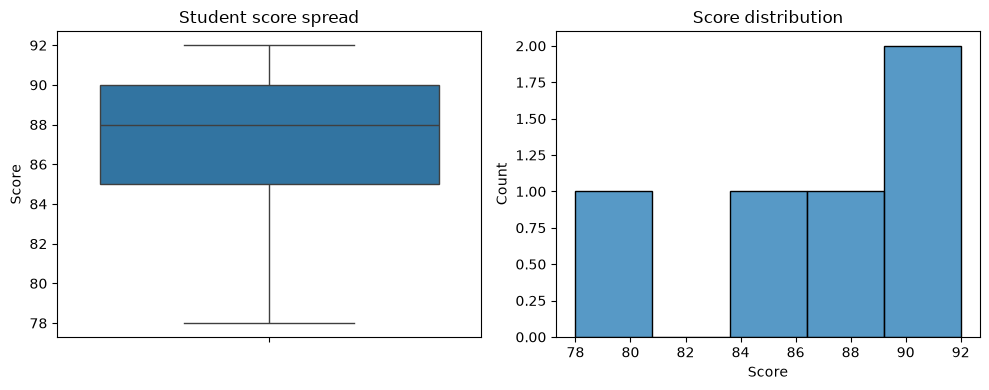

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({'Student': list('ABCDE'), 'Score': [85, 90, 78, 92, 88]})
print(df)
print('Mean:', df['Score'].mean())
print('Median:', df['Score'].median())
print('Mode(s):', df['Score'].mode().tolist(), '(all scores are unique)')
print('Quartiles:', df['Score'].quantile([.25,.5,.75]).to_dict())
print('Variance:', df['Score'].var())
print('Standard deviation:', df['Score'].std())
fig, axes = plt.subplots(1,2,figsize=(10,4))
sns.boxplot(y=df['Score'],ax=axes[0]);axes[0].set_title('Student score spread')
sns.histplot(df['Score'],bins=5,ax=axes[1]);axes[1].set_title('Score distribution')
plt.tight_layout();plt.show()

## Question 2: Insurance Claim Analysis

count      10.000000
mean     2540.000000
std      1113.752416
min      1200.000000
25%      1850.000000
50%      2300.000000
75%      2950.000000
max      5000.000000
Name: Claim_Amount, dtype: float64
Mode(s): [1200, 1500, 1800, 2000, 2100, 2500, 2800, 3000, 3500, 5000] (all values are unique)
Skewness: 1.1769889067215888
Potential outliers:  Claim_ID  Claim_Amount
        8          5000


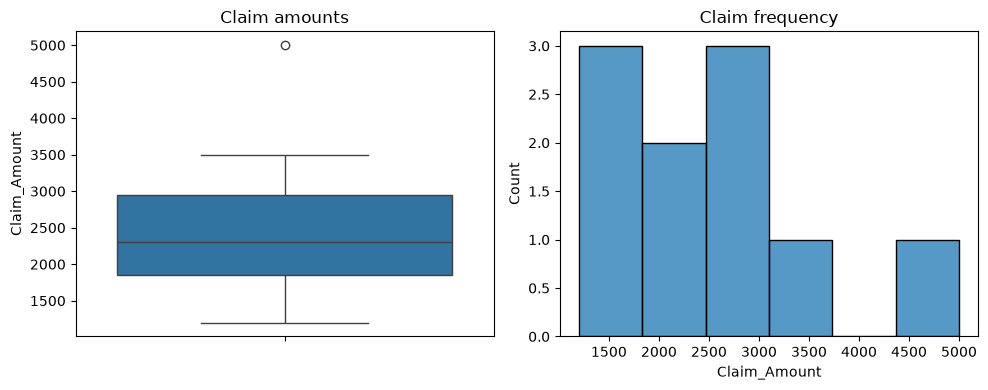

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({'Claim_ID': range(1,11), 'Claim_Amount':[2000,1500,3000,1200,1800,2500,3500,5000,2100,2800]})
print(df['Claim_Amount'].describe())
print('Mode(s):', df['Claim_Amount'].mode().tolist(), '(all values are unique)')
print('Skewness:', df['Claim_Amount'].skew())
q1,q3=df['Claim_Amount'].quantile([.25,.75]);iqr=q3-q1
print('Potential outliers:',df.loc[(df.Claim_Amount<q1-1.5*iqr)|(df.Claim_Amount>q3+1.5*iqr)].to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.boxplot(y=df['Claim_Amount'],ax=ax[0]);ax[0].set_title('Claim amounts')
sns.histplot(df['Claim_Amount'],bins=6,ax=ax[1]);ax[1].set_title('Claim frequency')
plt.tight_layout();plt.show()

## Question 3: Age, BMI and Blood Pressure

Correlation matrix:
                     Age       BMI  Blood_Pressure
Age             1.000000  0.989785        0.995160
BMI             0.989785  1.000000        0.978476
Blood_Pressure  0.995160  0.978476        1.000000
Rows flagged for review:
Empty DataFrame
Columns: [Age, BMI, Blood_Pressure]
Index: []


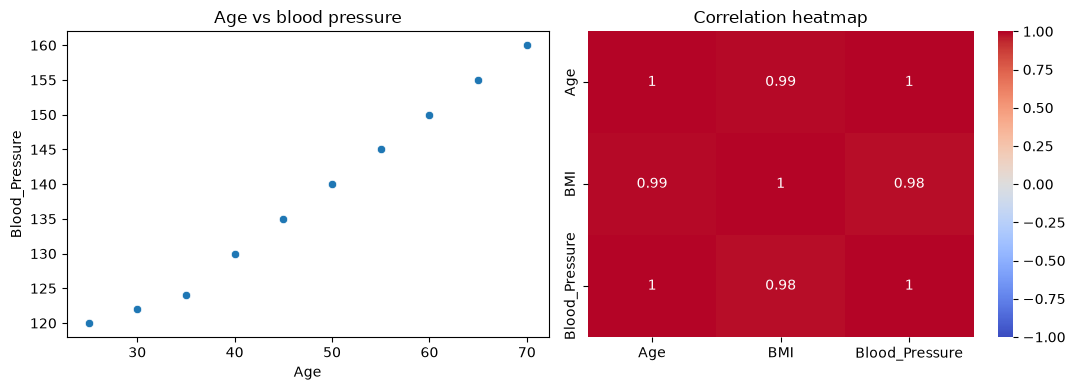

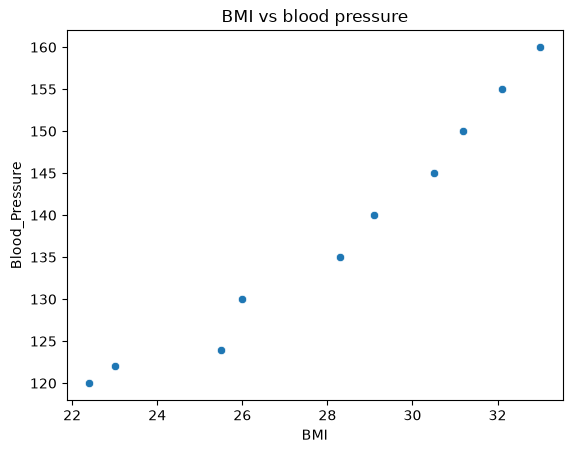

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.DataFrame({'Age':[25,30,35,40,45,50,55,60,65,70], 'BMI':[22.4,23.0,25.5,26.0,28.3,29.1,30.5,31.2,32.1,33.0], 'Blood_Pressure':[120,122,124,130,135,140,145,150,155,160]})
print('Correlation matrix:');print(df.corr(numeric_only=True))
# IQR screening: review flagged rows before excluding them.
flag=pd.Series(False,index=df.index)
for col in df.columns:
 q1,q3=df[col].quantile([.25,.75]);iqr=q3-q1
 flag |= (df[col]<q1-1.5*iqr)|(df[col]>q3+1.5*iqr)
print('Rows flagged for review:');print(df[flag])
clean=df[~flag].copy()
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.scatterplot(data=clean,x='Age',y='Blood_Pressure',ax=ax[0]);ax[0].set_title('Age vs blood pressure')
sns.heatmap(clean.corr(numeric_only=True),annot=True,cmap='coolwarm',vmin=-1,vmax=1,ax=ax[1]);ax[1].set_title('Correlation heatmap')
plt.tight_layout();plt.show()
sns.scatterplot(data=clean,x='BMI',y='Blood_Pressure');plt.title('BMI vs blood pressure');plt.show()

## Question 4: Regional Product Sales

count      8.000000
mean     218.750000
std       22.320714
min      180.000000
25%      207.500000
50%      220.000000
75%      232.500000
max      250.000000
Name: Sales, dtype: float64
Mode(s): [220]
Region totals:
Region
East     480
North    380
South    430
West     460
Name: Sales, dtype: int64
Product totals:
Product
A    910
B    840
Name: Sales, dtype: int64


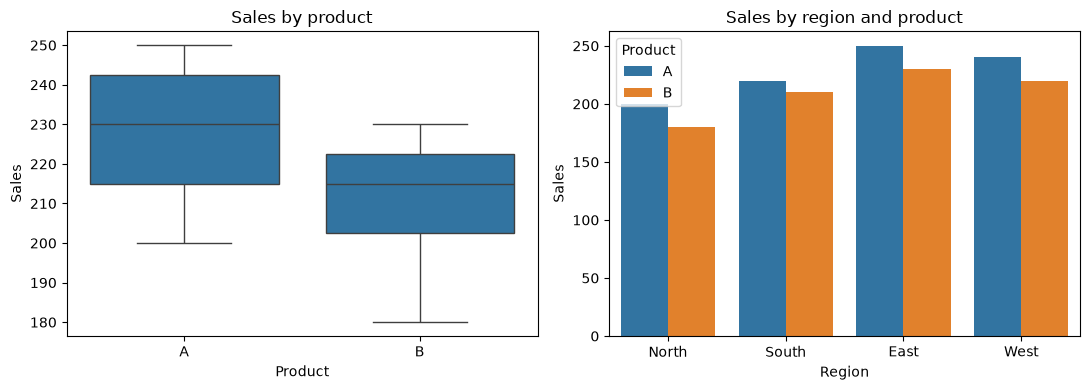

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.DataFrame({'Region':['North','South','East','West','North','South','East','West'], 'Product':['A','A','A','A','B','B','B','B'], 'Sales':[200,220,250,240,180,210,230,220]})
print(df['Sales'].describe())
print('Mode(s):',df['Sales'].mode().tolist())
print('Region totals:');print(df.groupby('Region')['Sales'].sum())
print('Product totals:');print(df.groupby('Product')['Sales'].sum())
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=df,x='Product',y='Sales',ax=ax[0]);ax[0].set_title('Sales by product')
sns.barplot(data=df,x='Region',y='Sales',hue='Product',errorbar=None,ax=ax[1]);ax[1].set_title('Sales by region and product')
plt.tight_layout();plt.show()

## Question 5: Product Price Distribution

mean     560.000000
min      430.000000
max     1200.000000
std      227.437415
Name: Price, dtype: float64
Potential outliers:
     Product  Price
5  Product F   1200


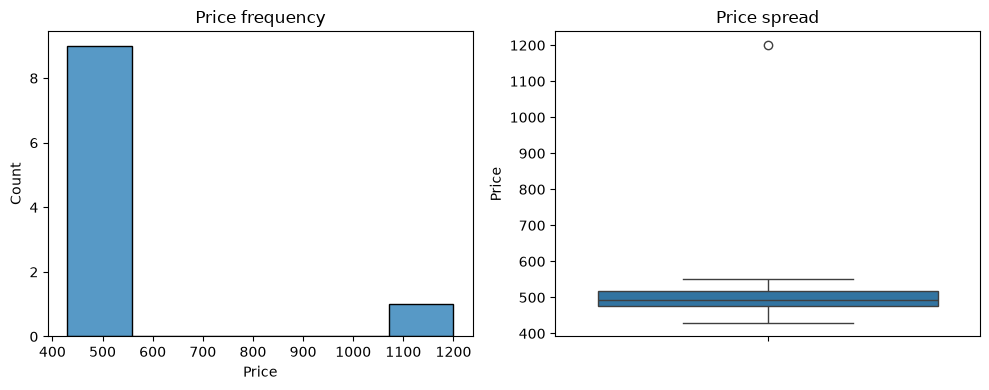

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.DataFrame({'Product':[f'Product {x}' for x in 'ABCDEFGHIJ'],'Price':[450,510,490,430,550,1200,480,495,475,520]})
print(df['Price'].agg(['mean','min','max','std']))
q1,q3=df.Price.quantile([.25,.75]);iqr=q3-q1
print('Potential outliers:');print(df[(df.Price<q1-1.5*iqr)|(df.Price>q3+1.5*iqr)])
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.histplot(df['Price'],bins=6,ax=ax[0]);ax[0].set_title('Price frequency')
sns.boxplot(y=df['Price'],ax=ax[1]);ax[1].set_title('Price spread')
plt.tight_layout();plt.show()